In [78]:
import pandas as pd
import json

def generate_provider_summary(row_configs, simple_mean=False):
    """
    Erstellt einen Pandas DataFrame mit der Provider-Zusammenfassung basierend auf JSON-Dateien.

    Parameter:
    - row_configs: Ein Dictionary, das den Namen der Zeile auf ein weiteres Dictionary abbildet 
                   (mit Dateipfad und individueller Filterfunktion).
                   Beispiel: 
                   {
                       'Schleswig-Holstein': {'file': 'de.json', 'filter': lambda df: df['region'] == 'Schleswig-Holstein'},
                       'Great Britain All': {'file': 'gb.json', 'filter': None}
                   }
    - simple_mean: Wenn False (Standard), wird der exakte gewichtete Durchschnitt über alle Daten berechnet.
                   Wenn True, wird der einfache ungewichtete Durchschnitt der Prozentzahlen berechnet.
    """
    rows = []
    all_dataframes = []

    for row_name, config in row_configs.items():
        filepath = config['file']
        filter_func = config.get('filter')

        # JSON-Datei einlesen
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)

        # Extrahiere die Kommunen-Datenbasis in einen DataFrame
        df = pd.DataFrame(data.get('municipalities', []))

        # Die individuelle Lambda-Filterung NUR für diesen spezifischen Datensatz anwenden
        if filter_func is not None and not df.empty:
            df = df[filter_func(df)]

        all_dataframes.append(df)

        n = len(df)
        
        # Sicherstellen, dass die abgefragten Spalten existieren
        ms = (df['provider'] == 'microsoft').sum() if 'provider' in df.columns else 0
        go = (df['provider'] == 'google').sum() if 'provider' in df.columns else 0
        aws = (df['provider'] == 'aws').sum() if 'provider' in df.columns else 0
        dom = (df['provider'] == 'domestic').sum() if 'provider' in df.columns else 0
        frgn = (df['provider'] == 'foreign').sum() if 'provider' in df.columns else 0
        unk = (df['provider'] == 'unknown').sum() if 'provider' in df.columns else 0

        # Prozentwerte & Durchschnitt berechnen
        us_pct = ((ms + go + aws) / n * 100) if n > 0 else 0.0
        dom_pct = (dom / n * 100) if n > 0 else 0.0
        conf = df['classification_confidence'].mean() if 'classification_confidence' in df.columns and n > 0 else 0.0
        gw_pct = (df['gateway'].notna().sum() / n * 100) if 'gateway' in df.columns and n > 0 else 0.0

        # Zeile für das aktuelle Land/Datei anfügen
        rows.append({
            'Country': row_name,
            'n': n,
            'MS': ms,
            'GO': go,
            'AWS': aws,
            'Dom': dom,
            'Frgn': frgn,
            'Unk': unk,
            'Dom %': dom_pct,
            'US %': us_pct,
            'Conf. %': conf,
            'GW %': gw_pct
        })

    # Gesamtsummenzeile ("Total") berechnen
    if all_dataframes:
        df_total = pd.concat(all_dataframes, ignore_index=True)
        n_tot = len(df_total)
        ms_tot = (df_total['provider'] == 'microsoft').sum() if 'provider' in df_total.columns else 0
        go_tot = (df_total['provider'] == 'google').sum() if 'provider' in df_total.columns else 0
        aws_tot = (df_total['provider'] == 'aws').sum() if 'provider' in df_total.columns else 0
        dom_tot = (df_total['provider'] == 'domestic').sum() if 'provider' in df_total.columns else 0
        frgn_tot = (df_total['provider'] == 'foreign').sum() if 'provider' in df_total.columns else 0
        unk_tot = (df_total['provider'] == 'unknown').sum() if 'provider' in df_total.columns else 0

        if simple_mean:
            # Einfacher arithmetischer Durchschnitt
            us_pct_tot = sum(r['US %'] for r in rows) / len(rows) if rows else 0.0
            dom_pct_tot = sum(r['Dom %'] for r in rows) / len(rows) if rows else 0.0
            conf_tot = sum(r['Conf. %'] for r in rows) / len(rows) if rows else 0.0
            gw_pct_tot = sum(r['GW %'] for r in rows) / len(rows) if rows else 0.0
        else:
            # Gewichteter Durchschnitt (exakt für die Gesamtmenge der gefilterten Daten)
            us_pct_tot = ((ms_tot + go_tot + aws_tot) / n_tot * 100) if n_tot > 0 else 0.0
            dom_pct_tot = (dom_tot / n_tot * 100) if n_tot > 0 else 0.0
            conf_tot = df_total['classification_confidence'].mean() if 'classification_confidence' in df_total.columns and n_tot > 0 else 0.0
            gw_pct_tot = (df_total['gateway'].notna().sum() / n_tot * 100) if 'gateway' in df_total.columns and n_tot > 0 else 0.0

        rows.append({
            'Country': 'Gesamt',
            'n': n_tot,
            'MS': ms_tot,
            'GO': go_tot,
            'AWS': aws_tot,
            'Dom': dom_tot,
            'Frgn': frgn_tot,
            'Unk': unk_tot,
            'Dom %': dom_pct_tot,
            'US %': us_pct_tot,
            'Conf. %': conf_tot,
            'GW %': gw_pct_tot
        })

    df_res = pd.DataFrame(rows)

    # Formatierung als Prozent-Strings
    for col in ['Dom %', 'US %', 'Conf. %', 'GW %']:
        df_res[col] = df_res[col].apply(lambda x: f"{x:.1f}%" if pd.notnull(x) else "0.0%")

    df_res.set_index('Country', inplace=True)

    return df_res

In [79]:

configs_tiers = {
    'DE Gem (Apr 26)': {
        'file': 'providers/providers_de.min.json',
        'filter': lambda df: (~df['code'].str.endswith('000', na=False)) & (df['code'].str.len() == 8)
    },
    'DE Krf-St. (Apr 26)': {
        'file': 'providers/providers_de.min.json',
        'filter': lambda df: df['code'].str.endswith('000', na=False)
    },
    'DE LK (Sep 26)': {
        'file': 'providers/providers_de.min.json',
        'filter': lambda df: (df['code'].str.len() == 5)
    },
    'GB Unitary (Aug 26)': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: (~df['code'].str.startswith('E07', na=False)) & (~df['code'].str.startswith('E10', na=False))
    },
    'GB Counties (Aug 26)': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: df['code'].str.startswith('E10', na=False)
    },
    'GB Districts (Aug 26)': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: df['code'].str.startswith('E07', na=False)
    }
}

# DataFrame generieren
df_provider_de_gb_tiers = generate_provider_summary(configs_tiers)
df_provider_de_gb_tiers

,n,MS,GO,AWS,Dom,Frgn,Unk,Dom %,US %,Conf. %,GW %
Country,,,,,,,,,,,
DE Gem (Apr 26),11021,788,7,0,9547,147,532,86.6%,7.2%,75.7%,5.3%
DE Krf-St. (Apr 26),107,5,1,0,99,0,2,92.5%,5.6%,78.9%,2.8%
DE LK (Sep 26),294,5,0,0,281,1,7,95.6%,1.7%,78.2%,3.1%
GB Unitary (Aug 26),197,164,3,0,20,0,10,10.2%,84.8%,87.2%,20.3%
GB Counties (Aug 26),21,19,0,0,2,0,0,9.5%,90.5%,93.0%,14.3%
GB Districts (Aug 26),164,139,3,3,16,0,3,9.8%,88.4%,83.4%,47.6%
Gesamt,11804,1120,14,3,9965,148,554,84.4%,9.6%,76.1%,6.1%


In [80]:
# Konfiguration der gewünschten Tabellenzeilen
configs_total = {
        # Zeile 3: Großbritannien, komplett OHNE Filter

    'DE Gesamt': {
    'file': 'providers/providers_de.min.json',
    'filter': None
    },
    'GB Gesamt': {
    'file': 'providers/providers_gb.min.json',
    'filter': None
    }

}

# DataFrame generieren
df_provider_de_gb_total = generate_provider_summary(configs_total)
df_provider_de_gb_total

,n,MS,GO,AWS,Dom,Frgn,Unk,Dom %,US %,Conf. %,GW %
Country,,,,,,,,,,,
DE Gesamt,11422,798,8,0,9927,148,541,86.9%,7.1%,75.8%,5.2%
GB Gesamt,382,322,6,3,38,0,13,9.9%,86.6%,85.9%,31.7%
Gesamt,11804,1120,14,3,9965,148,554,84.4%,9.6%,76.1%,6.1%


In [81]:
# Konfiguration der gewünschten Tabellenzeilen
configs = {
        # Zeile 3: Großbritannien, komplett OHNE Filter
    'DE old': {
        'file': 'providers/providers_de_orig.min.json',
        'filter': None
    },
    # Zeile 1: Filtert Deutschland nur nach Schleswig-Holstein
    'AT': {
        'file': 'providers/providers_at.min.json',
        'filter': None
    },
    # Zeile 2: Filtert Deutschland nur nach Codes, die mit "09" (Bayern) beginnen
    'CH': {
        'file': 'providers/providers_ch.min.json',
        'filter': None
    }

}

# DataFrame generieren
df_final = generate_provider_summary(configs)
df_final

,n,MS,GO,AWS,Dom,Frgn,Unk,Dom %,US %,Conf. %,GW %
Country,,,,,,,,,,,
DE old,11129,793,8,0,9647,147,534,86.7%,7.2%,75.7%,5.3%
AT,2092,1401,0,0,604,36,51,28.9%,67.0%,85.2%,36.8%
CH,2110,1099,4,22,878,14,93,41.6%,53.3%,84.9%,9.6%
Gesamt,15331,3293,12,22,11129,197,678,72.6%,21.7%,78.3%,10.2%


In [86]:

configs_regions_uk = {
    'Wales': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: (df['region']== "Wales")
    },
    'NIR': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: (df['region'] == "Northern Ireland")
    },
    'Schottland': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: (df['region'] == "Scotland")
    },
    'England': {
        'file': 'providers/providers_gb.min.json',
        'filter': lambda df: (df['region'] == "England")
    }
}

# DataFrame generieren
df_provider_de_gb_region = generate_provider_summary(configs_regions_uk)
df_provider_de_gb_region

,n,MS,GO,AWS,Dom,Frgn,Unk,Dom %,US %,Conf. %,GW %
Country,,,,,,,,,,,
Wales,22,18,0,0,2,0,2,9.1%,81.8%,81.9%,36.4%
NIR,11,10,0,0,0,0,1,0.0%,90.9%,79.0%,45.5%
Schottland,32,26,0,0,5,0,1,15.6%,81.2%,86.4%,21.9%
England,317,268,6,3,31,0,9,9.8%,87.4%,86.3%,31.9%
Gesamt,382,322,6,3,38,0,13,9.9%,86.6%,85.9%,31.7%


In [82]:
from pathlib import Path
import re
from typing import List, Optional, Union
import matplotlib.pyplot as plt
import pandas as pd

# ==============================================================================
# 1. HILFSFUNKTION: PROZENTWERT EXTRAHIEREN
# ==============================================================================

def extract_percentage(val) -> float:
    """Extrahiert den Prozentwert aus Strings wie '87.5% (9974)', '12.1%' oder '87.5'."""
    if pd.isna(val):
        return 0.0
    s = str(val).strip()

    # 1. Sucht nach Zahlen vor einem Prozentzeichen (z. B. '87.5%')
    match = re.search(r"([\d\.,]+)%", s)
    if match:
        return float(match.group(1).replace(",", "."))

    # 2. Reiner Zahlenwert
    match_num = re.search(r"^[\d\.,]+$", s)
    if match_num:
        try:
            return float(s.replace(",", "."))
        except ValueError:
            return 0.0
    return 0.0


# ==============================================================================
# 2. GENERISCHER TABELLEN-RENDERER (HEATMAP + BOOKTABS)
# ==============================================================================

def render_table_to_image(
    df_input: pd.DataFrame,
    filename: str = "tabelle_bachelorarbeit.png",
    dpi: int = 800,
    red_keywords: Optional[List[str]] = None,
    divider_rows: Optional[List[int]] = None,
    divider_cols: Optional[List[int]] = None,
    font_size: int = 14,
    caption: Optional[str] = None,          # Der Text für den Untertitel
    caption_fontsize: Optional[int] = 14,
    caption_pos: Optional[float] = -0.05,
    index_header: Optional[str] = None, 
    row_labels: Optional[List[str]] = None,
    hide_index: bool = False,
    exclude_color_cols: Optional[List[str]] = None,
    bold_rows: Optional[List[int]] = None,             # NEU: Liste der zu fettenden Zeilen-Indizes (0-basiert)
    bold_cols: Optional[List[Union[str, int]]] = None, # NEU: Liste der zu fettenden Spalten (Namen oder Indizes)
    disable_colors: bool = False                       # NEU: Schaltet die Heatmap-Einfärbung komplett aus
):
    """Rendert einen DataFrame als hochauflösendes Bild im wissenschaftlichen Booktabs-Look
    mit 2-Ebenen-Heatmap (Blau für Standard, Rot für Warnungen/Fehler).
    """
    
    # Standardmäßig rot zu schattierende Spalten
    if red_keywords is None:
        red_keywords = [
            "fehler",
            "warnung",
            "nodkim",
        ]
    red_keywords = [kw.lower() for kw in red_keywords]

    if exclude_color_cols is None:
        exclude_color_cols = []
    exclude_color_cols = [kw.lower() for kw in exclude_color_cols]
    
    # Vertikale Trennlinien
    if divider_cols is None:
        divider_cols = [0] if hide_index else [0, 1]
    
    # Matplotlib LaTeX / Serif Setup
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["DejaVu Serif", "Arial", "Times New Roman"]
    plt.rcParams["mathtext.fontset"] = "cm"

    df_plot = df_input.copy() # Kopie, um das Original nicht zu verändern
    
    # Eigene Zeilennamen setzen (falls übergeben)
    if row_labels is not None:
        if len(row_labels) == len(df_plot):
            df_plot.index = row_labels
        else:
            raise ValueError(f"Anzahl der row_labels ({len(row_labels)}) passt nicht zur Zeilenanzahl ({len(df_plot)}).")

    if not hide_index:
        df_plot = df_plot.reset_index()
        final_header_name = index_header if index_header else (df_input.index.name if df_input.index.name else "Segment")
        old_index_col_name = df_plot.columns[0]
        df_plot.rename(columns={old_index_col_name: final_header_name}, inplace=True)
        
        index_col_idx = 0 # Der Index ist in Spalte 0
    else:
        # Index wird weggelassen. df_plot.values nutzt automatisch nur die Daten-Spalten
        index_col_idx = -1 # Markiert, dass wir keinen sichtbaren Index haben

    num_rows, num_cols = df_plot.shape

    # ==========================================================================
    # DYNAMISCHE SPALTENBREITEN BERECHNEN (Platzsparend)
    # ==========================================================================
    # Wir messen die Länge des Textes im Header und in allen Zeilen pro Spalte
    col_widths = []
    for col in df_plot.columns:
        # Finde den längsten String (Header oder Inhalt)
        max_len = max([len(str(x)) for x in df_plot[col].values] + [len(str(col))])
        # Skalierungsfaktor für die Breite (0.015 bis 0.025 ist meist passend für Matplotlib)
        col_widths.append(max_len * 0.018 + 0.03) 

    # Automatische Skalierung der Bildabmessungen basierend auf den exakten Spaltenbreiten
    fig_width = sum(col_widths) * 10 + 1.0 # *10 als Skalierungsfaktor der Figur, +1.0 Margin
    fig_height = max(2.8, num_rows * 0.48 + 1.2)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.axis("off")

    # ==========================================================================
    # LAYER 1: HINTERGRUND (Heatmap-Farben)
    # ==========================================================================
    # Nur ausführen, wenn Farben nicht deaktiviert sind
    if not disable_colors:
        table_bg = ax.table(
            cellText=df_plot.values,
            colLabels=df_plot.columns,
            loc="center",
            cellLoc="center",
            colWidths=col_widths # NEU: Angepasste Spaltenbreiten
        )
        table_bg.auto_set_font_size(False)
        table_bg.set_fontsize(font_size)
        table_bg.scale(0.9, 2.0)

        # Erkennt Zwischensummen wie 'Gesamt DE' automatisch und zieht dort eine Midrule
        if divider_rows is None:
            divider_rows = [
                r_idx for r_idx, val in enumerate(df_plot.iloc[:, 0], start=1) 
                if any(k in str(val).lower() for k in ['gesamt', 'alle', 'anzahl', 'total']) and r_idx != num_rows
            ]
        
        for (row, col), cell in table_bg.get_celld().items():
            cell.set_edgecolor("none")  # Keine Ränder in Layer 1
            cell.get_text().set_text("")  # Text leeren

            col_name = str(df_plot.columns[col]).lower()

            # Prüfen, ob Spalte auf der Ausnahmen-Liste steht
            is_excluded = any(kw in col_name for kw in exclude_color_cols)
            
            # Header (row 0), Spalte 0 (Labels) und Gesamtspalten bleiben weiß
            if (
                row == 0
                or col == 0
                or "gesamt" in col_name
                or "total" in col_name
                or "(n)" in col_name
                or is_excluded
            ):
                cell.set_facecolor("white")
            else:
                text_value = df_plot.iloc[row - 1, col]
                pct = extract_percentage(text_value)

                # Prüfen, ob die Spalte negativ besetzt ist -> Red Colormap
                is_red = any(kw in col_name for kw in red_keywords)
                cmap = plt.colormaps["Reds" if is_red else "Blues"]

                # Intensität: Skalierung anpassen, damit Schrift gut lesbar bleibt
                max_intensity = 0.5 if is_red else 0.4
                intensity = min(1.0, (pct / 100.0) * max_intensity)
                cell.set_facecolor(cmap(intensity))

    # ==========================================================================
    # LAYER 2: VORDERGRUND (Text & Booktabs-Ränder)
    # ==========================================================================
    table_fg = ax.table(
        cellText=df_plot.values,
        colLabels=df_plot.columns,
        loc="center",
        cellLoc="center",
        colWidths=col_widths # NEU: Angepasste Spaltenbreiten
    )
    table_fg.auto_set_font_size(False)
    table_fg.set_fontsize(font_size)
    table_fg.scale(0.9, 2.0)

    # Wenn divider_rows noch nicht gesetzt wurde (weil Farben deaktiviert waren), hole es nach
    if divider_rows is None:
        divider_rows = [
            r_idx for r_idx, val in enumerate(df_plot.iloc[:, 0], start=1) 
            if any(k in str(val).lower() for k in ['gesamt', 'alle', 'anzahl', 'total']) and r_idx != num_rows
        ]

    # ==========================================================================
    # NEU: Spalten-Indizes für bold_cols ermitteln (erlaubt Strings und Ints)
    # ==========================================================================
    bold_col_indices = []
    if bold_cols is not None:
        for b_col in bold_cols:
            if isinstance(b_col, int) and b_col < len(df_plot.columns):
                bold_col_indices.append(b_col)
            elif isinstance(b_col, str) and b_col in df_plot.columns:
                bold_col_indices.append(list(df_plot.columns).index(b_col))
                
    if bold_rows is None:
        bold_rows = []
    # ==========================================================================

    for (row, col), cell in table_fg.get_celld().items():
        cell.set_facecolor("none")  # Transparent
        cell.set_linewidth(1.0)

        edges = ""

        # Header: Oben und unten doppelte/starke Linie (Toprule / Midrule)
        if row == 0:
            edges += "BT"
            cell.set_linewidth(1.4)
            cell.get_text().set_fontweight("bold")
        # Letzte Tabellenzeile: Abschlusslinie unten (Bottomrule)
        elif row == num_rows:
            edges += "B"
            cell.set_linewidth(1.4)

        # Benutzerdefinierte horizontale Trennlinien (z. B. zwischen GB und DE)
        if divider_rows and row in divider_rows:
            edges += "B"

        # Trennlinien vertikal
        if divider_cols and col in divider_cols:
            edges += "R"
        
        # Vertikale Trennlinien nach Spalte 0 (Segment) und Spalte 1 (Gesamt N)
        if (col == 0 or col == 1) and not divider_cols:
            edges += "R"

        # Ausrichtung & Typografie
        if col == 0:
            # Spalte 0 immer linksbündig
            cell.set_text_props(ha="left")
            if row > 0:
                # Summen- / Übergeordnete Zeilen (z. B. 'Alle DE', 'Gesamt') automatisch fetten
                val_str = str(df_plot.iloc[row - 1, 0]).lower()
                if any(k in val_str for k in ["alle", "gesamt", "total"]):
                    cell.get_text().set_fontweight("bold")

        # ==========================================================================
        # Zusätzliches Fetten von bestimmten Zeilen und Spalten
        # (row > 0 überspringt den Header, row - 1 ist der 0-basierte Daten-Index)
        # ==========================================================================
        if (row > 0 and (row - 1) in bold_rows) or (col in bold_col_indices):
            cell.get_text().set_fontweight("bold")

        cell.visible_edges = edges

    # ==========================================================================
    # LAYER 3: UNTERTITEL (CAPTION / FOOTNOTE)
    # ==========================================================================
    if caption:
        if caption_fontsize is None:
            caption_fontsize = max(8, font_size - 4) # Standardmäßig etwas kleiner als Tabellentext
        if caption_pos is None:
            caption_pos = -0.05
        
        plt.figtext(
            0.05, caption_pos,            # x, y Position (linksbündig, leicht unterhalb des Bildrandes)
            caption, 
            ha="left",                    # Links ausgerichtet (alternativ "center" und x=0.5)
            fontsize=caption_fontsize, 
            style="italic",               # Kursiv sieht für wissenschaftliche Untertitel oft gut aus
            wrap=True                     # Erlaubt Zeilenumbrüche, falls der Text sehr lang ist
        )

    # WICHTIG: pad_inches hinzufügen, damit der Text unten nicht abgeschnitten wird!
    plt.tight_layout()
    plt.savefig(filename, dpi=dpi, bbox_inches="tight", pad_inches=0.15) 
    plt.show()
    plt.close()
    print(f"Tabelle erfolgreich gespeichert unter: {filename}")

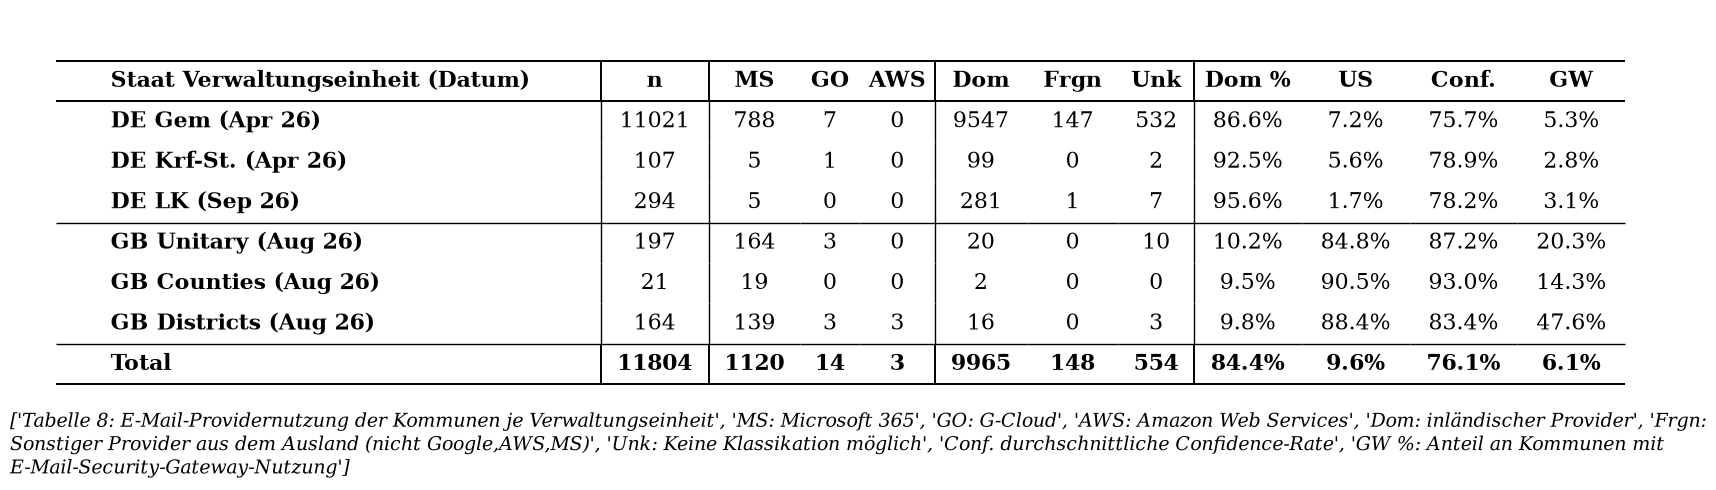

Tabelle erfolgreich gespeichert unter: abbildung_providers.png


In [94]:
render_table_to_image(
    df_provider_de_gb,
    filename="abbildung_providers.png",
    divider_rows=[3,6],  
    dpi=800,
    divider_cols=[0,1,4,7],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Staat Verwaltungseinheit (Datum)",
    caption = ["Tabelle 8: E-Mail-Providernutzung der Kommunen je Verwaltungseinheit", "MS: Microsoft 365", "GO: G-Cloud", "AWS: Amazon Web Services", "Dom: inländischer Provider", "Frgn: Sonstiger Provider aus dem Ausland (nicht Google,AWS,MS)"
              , "Unk: Keine Klassikation möglich", "Conf. durchschnittliche Confidence-Rate", "GW %: Anteil an Kommunen mit E-Mail-Security-Gateway-Nutzung"
              ],
    caption_pos = -0.05,
    exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    #hide_index = True,
    font_size = 16,
    bold_rows = [6],
    bold_cols = [0],
    disable_colors = True

)

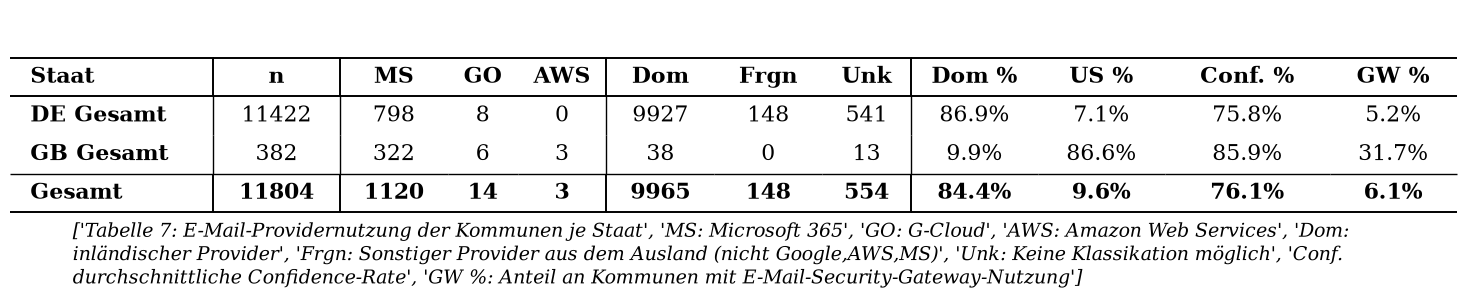

Tabelle erfolgreich gespeichert unter: abbildung_providers.png


In [91]:
render_table_to_image(
    df_provider_de_gb_total,
    filename="abbildung_providers.png",
    divider_rows=[2],  
    dpi=800,
    divider_cols=[0,1,4,7],
 #   row_labels= [1,2,3,"","Fehler gesamt"],
    index_header= "Staat",
    caption = ["Tabelle 7: E-Mail-Providernutzung der Kommunen je Staat", "MS: Microsoft 365", "GO: G-Cloud", "AWS: Amazon Web Services", "Dom: inländischer Provider", "Frgn: Sonstiger Provider aus dem Ausland (nicht Google,AWS,MS)"
              , "Unk: Keine Klassikation möglich", "Conf. durchschnittliche Confidence-Rate", "GW %: Anteil an Kommunen mit E-Mail-Security-Gateway-Nutzung"
              ],
    caption_pos = -0.03,
   # exclude_color_cols = ["Anzahl (GB)","Anzahl (DE)", "DE Anteil","GB Anteil", "Fehlertyp"],
    #hide_index = True,
    font_size = 16,
    bold_rows = [2],
    bold_cols = [0],
    disable_colors = True

)